# FLoRA: Learning Temporal Logic Formulas

This notebook demonstrates the full FLoRA workflow:
1. Define a target temporal logic formula
2. Generate positive/negative synthetic data
3. Train a `LogicNetwork` to learn the formula structure
4. Extract an interpretable formula via discretization + sympy
5. Evaluate classification accuracy

**Paper:** "FLoRA: A Framework for Learning Scoring Rules in Autonomous Driving Planning Systems" (arXiv 2502.11352)

In [1]:
import torch
import matplotlib.pyplot as plt

from flora import DEVICE
from flora.network import LogicNetwork
from flora.train import generate_data_G_and_F, generate_data_G_neg_and_F, generate_data_GF, train

print(f"Device: {DEVICE}")

Device: cuda


In [2]:
def plot_training(losses, title=""):
    plt.figure(figsize=(8, 3))
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def evaluate(net, pos_test, neg_test):
    with torch.no_grad():
        pos_scores = net(pos_test)
        neg_scores = net(neg_test)
    pos_acc = (pos_scores > 0).float().mean().item()
    neg_acc = (neg_scores < 0).float().mean().item()
    print(f"  Positive accuracy: {pos_acc:.0%}")
    print(f"  Negative accuracy: {neg_acc:.0%}")
    return pos_scores, neg_scores

def plot_scores(pos_scores, neg_scores, title=""):
    fig, ax = plt.subplots(1, 1, figsize=(8, 3))
    ax.hist(pos_scores.cpu().numpy(), bins=30, alpha=0.6, label="Positive", color="green")
    ax.hist(neg_scores.cpu().numpy(), bins=30, alpha=0.6, label="Negative", color="red")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Score")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

## Example 1: G(P0) ∧ F(P1)

**Target formula:** "P0 is **always** positive AND P1 is **eventually** positive"

- `G` (Globally) = min over all future timesteps
- `F` (Finally) = max over all future timesteps
- Positive data: P0 always > 0, P1 has at least one positive spike
- Negative data: P0 has a negative dip (violates G)

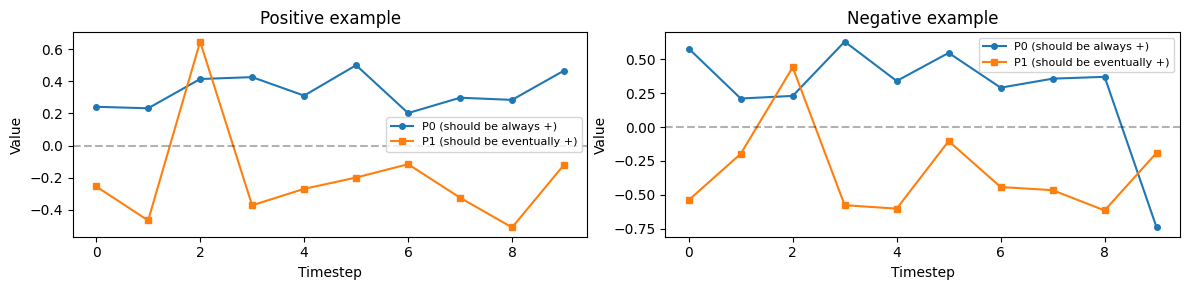

In [3]:
torch.manual_seed(42)
pos, neg = generate_data_G_and_F(1000, 2, 10, g_idx=0, f_idx=1)

# Visualize one positive and one negative example
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, data, title in [(axes[0], pos[0], "Positive example"), (axes[1], neg[0], "Negative example")]:
    ax.plot(data[0].cpu(), label="P0 (should be always +)", marker="o", markersize=4)
    ax.plot(data[1].cpu(), label="P1 (should be eventually +)", marker="s", markersize=4)
    ax.axhline(0, color="black", linestyle="--", alpha=0.3)
    ax.set_title(title)
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Value")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Extracted formula: G(goal_reached) | G(safe_distance)


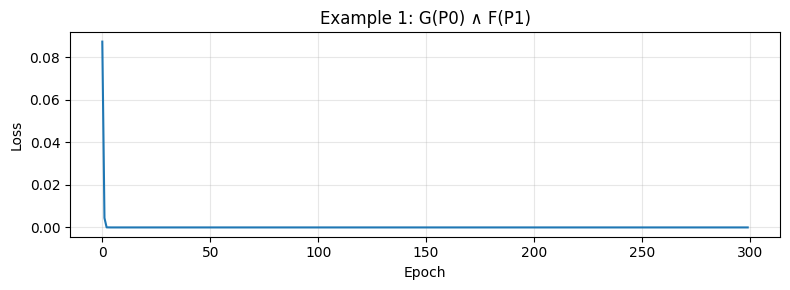

  Positive accuracy: 100%
  Negative accuracy: 100%


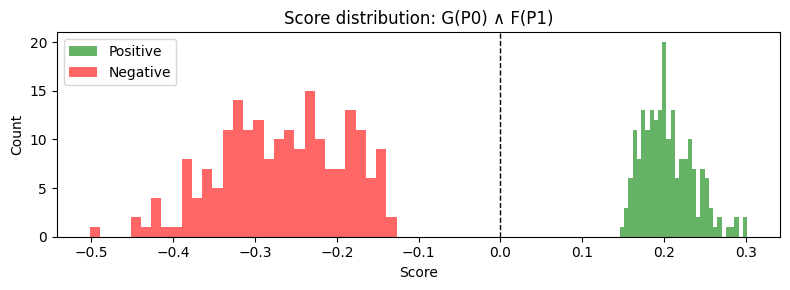

In [4]:
net1 = LogicNetwork(n_predicates=2, n_temporal_layers=1, hardness=10.0).to(DEVICE)
losses1 = train(net1, pos, neg, lr=0.05, epochs=300, batch_size=64)

formula1 = net1.extract(["safe_distance", "goal_reached"])
print(f"Extracted formula: {formula1}")

plot_training(losses1, "Example 1: G(P0) ∧ F(P1)")

pos_test, neg_test = generate_data_G_and_F(200, 2, 10, g_idx=0, f_idx=1)
pos_scores, neg_scores = evaluate(net1, pos_test, neg_test)
plot_scores(pos_scores, neg_scores, "Score distribution: G(P0) ∧ F(P1)")

## Example 2: G(~P0) ∧ F(P1) -- Negation Gate

**Target formula:** "P0 is **always negative** AND P1 is **eventually** positive"

Tests the **negation gate** (`tanh(w)` sign control): the network must learn to flip P0's sign before applying G.

- Positive data: P0 always < 0, P1 eventually > 0
- Negative data: P0 has a positive spike (violates G(~P0))

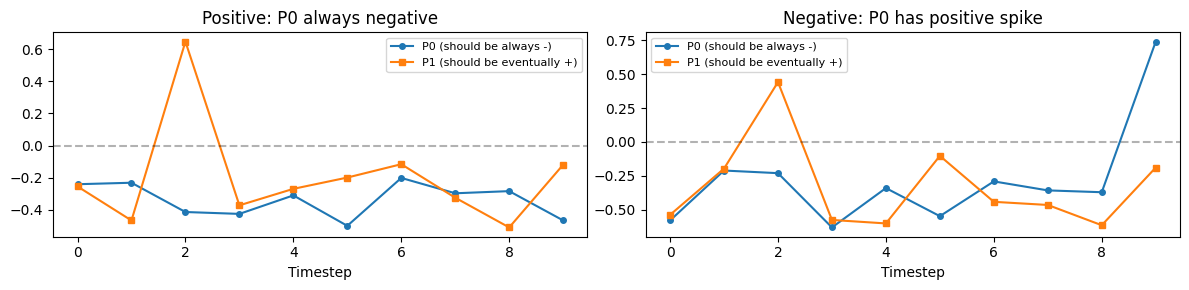

In [5]:
torch.manual_seed(42)
pos_neg, neg_neg = generate_data_G_neg_and_F(1000, 2, 10, g_neg_idx=0, f_idx=1)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, data, title in [(axes[0], pos_neg[0], "Positive: P0 always negative"),
                         (axes[1], neg_neg[0], "Negative: P0 has positive spike")]:
    ax.plot(data[0].cpu(), label="P0 (should be always -)", marker="o", markersize=4)
    ax.plot(data[1].cpu(), label="P1 (should be eventually +)", marker="s", markersize=4)
    ax.axhline(0, color="black", linestyle="--", alpha=0.3)
    ax.set_title(title)
    ax.set_xlabel("Timestep")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Extracted formula: G(goal_reached) | ~F(obstacle_nearby)


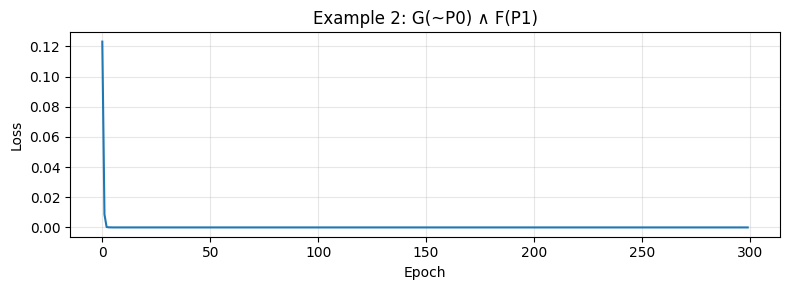

  Positive accuracy: 100%
  Negative accuracy: 100%


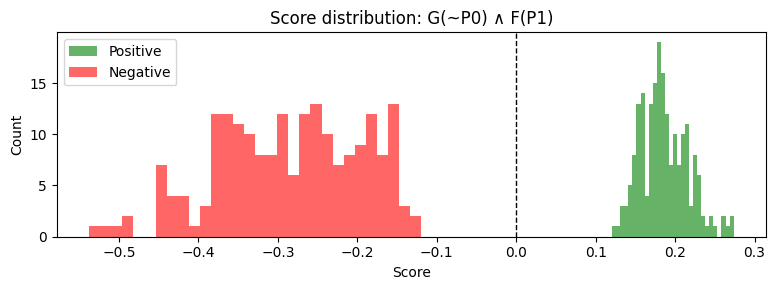

In [6]:
net_neg = LogicNetwork(n_predicates=2, n_temporal_layers=1, hardness=10.0).to(DEVICE)
losses_neg = train(net_neg, pos_neg, neg_neg, lr=0.05, epochs=300, batch_size=64)

formula_neg = net_neg.extract(["obstacle_nearby", "goal_reached"])
print(f"Extracted formula: {formula_neg}")

plot_training(losses_neg, "Example 2: G(~P0) ∧ F(P1)")

pos_test_neg, neg_test_neg = generate_data_G_neg_and_F(200, 2, 10, g_neg_idx=0, f_idx=1)
pos_scores_neg, neg_scores_neg = evaluate(net_neg, pos_test_neg, neg_test_neg)
plot_scores(pos_scores_neg, neg_scores_neg, "Score distribution: G(~P0) ∧ F(P1)")

## Example 3: G(F(P0)) ∧ F(P1) -- Nested Temporal Operators

**Target formula:** "P0 is **recurrently** positive (every suffix has a positive value) AND P1 is eventually positive"

This requires **2 temporal layers** to compose G(F(...)):
- Layer 0 applies F to P0
- Layer 1 applies G on top of that

We use **hardness annealing** (5 -> 30) for smoother training.

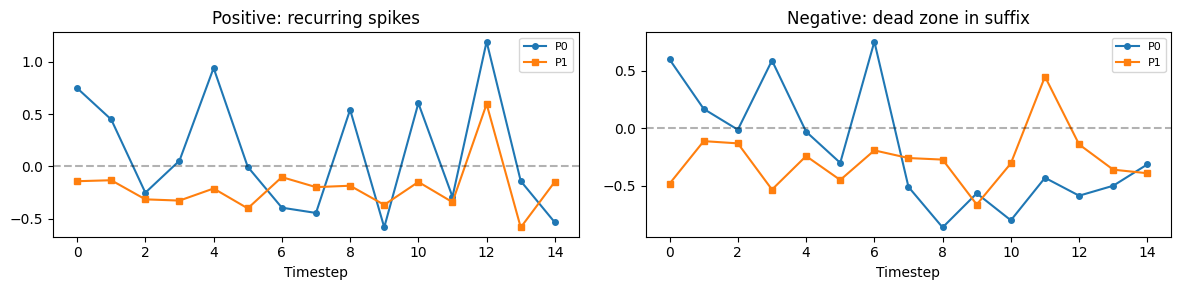

In [7]:
torch.manual_seed(42)
pos2, neg2 = generate_data_GF(1000, 2, 15, gf_idx=0, f_idx=1)

# Visualize: positive has recurring spikes, negative has a dead zone
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, data, title in [(axes[0], pos2[0], "Positive: recurring spikes"), (axes[1], neg2[0], "Negative: dead zone in suffix")]:
    ax.plot(data[0].cpu(), label="P0", marker="o", markersize=4)
    ax.plot(data[1].cpu(), label="P1", marker="s", markersize=4)
    ax.axhline(0, color="black", linestyle="--", alpha=0.3)
    ax.set_title(title)
    ax.set_xlabel("Timestep")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Extracted formula: F(G(visits_goal)) & F(~in_lane)


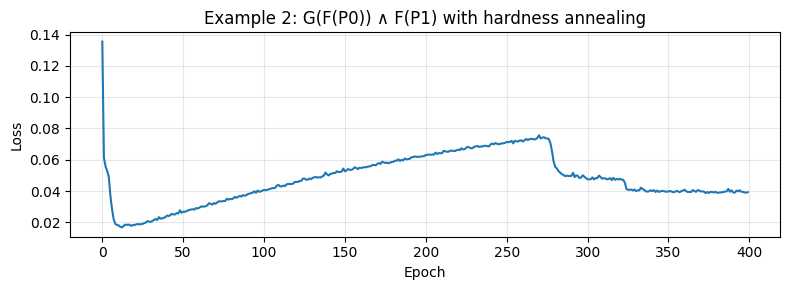

  Positive accuracy: 88%
  Negative accuracy: 98%


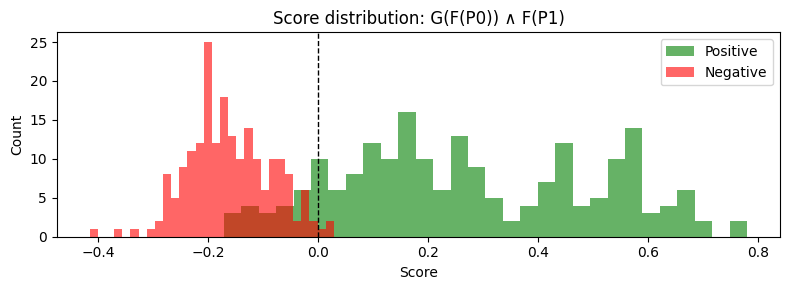

In [8]:
net2 = LogicNetwork(n_predicates=2, n_temporal_layers=2, hardness=10.0).to(DEVICE)
losses2 = train(net2, pos2, neg2, lr=0.05, epochs=400, batch_size=64, anneal_hardness=(5.0, 30.0))

formula2 = net2.extract(["visits_goal", "in_lane"])
print(f"Extracted formula: {formula2}")

plot_training(losses2, "Example 2: G(F(P0)) ∧ F(P1) with hardness annealing")

pos_test2, neg_test2 = generate_data_GF(200, 2, 15, gf_idx=0, f_idx=1)
pos_scores2, neg_scores2 = evaluate(net2, pos_test2, neg_test2)
plot_scores(pos_scores2, neg_scores2, "Score distribution: G(F(P0)) ∧ F(P1)")

## Example 4: 6-Predicate Multi-Rule Formula

**Target:** 3 independent G/F pairs combined with AND:

`G(safe_dist) ∧ F(reach_goal) ∧ G(in_lane) ∧ F(speed_ok) ∧ G(no_jerk) ∧ F(progress)`

Tests the network's ability to learn multiple rules simultaneously via the propositional and aggregation layers.

In [9]:
torch.manual_seed(42)
N, T, n = 6, 10, 1000

pos3 = torch.rand(n, N, T, device=DEVICE) * 2 - 1
neg3 = torch.rand(n, N, T, device=DEVICE) * 2 - 1

# Even indices (0,2,4): always positive (G predicates)
# Odd indices (1,3,5): eventually positive (F predicates)
for i in [0, 2, 4]:
    pos3[:, i, :] = torch.abs(torch.randn(n, T, device=DEVICE)) * 0.3 + 0.2
    neg3[:, i, :] = torch.abs(torch.randn(n, T, device=DEVICE)) * 0.3 + 0.2
for i in [1, 3, 5]:
    for data in [pos3, neg3]:
        data[:, i, :] = -torch.abs(torch.randn(n, T, device=DEVICE)) * 0.3 - 0.1
        spike_t = torch.randint(0, T, (n,))
        for j in range(n):
            data[j, i, spike_t[j]] = torch.abs(torch.randn(1)).item() * 0.3 + 0.3

# Negative: dip one random G-predicate per sample
dip_pred = torch.randint(0, 3, (n,)) * 2
dip_t = torch.randint(0, T, (n,))
for j in range(n):
    neg3[j, dip_pred[j], dip_t[j]] = -torch.abs(torch.randn(1)).item() * 0.3 - 0.2

print(f"Data shapes — pos: {pos3.shape}, neg: {neg3.shape}")

Data shapes — pos: torch.Size([1000, 6, 10]), neg: torch.Size([1000, 6, 10])


Extracted formula:
  (G(in_lane) | G(speed_ok)) & (G(no_jerk) | G(progress)) & (G(reach_goal) | G(safe_dist))


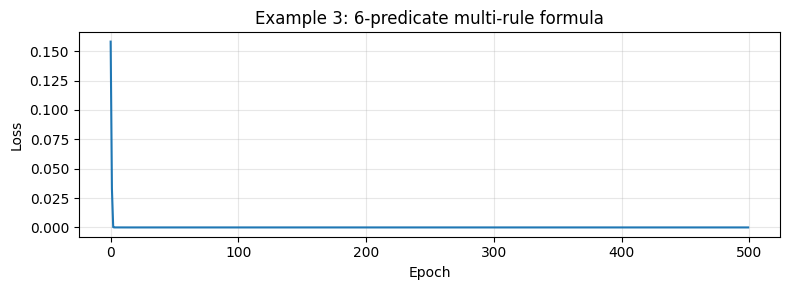

In [10]:
net3 = LogicNetwork(n_predicates=N, n_temporal_layers=1, hardness=10.0).to(DEVICE)
losses3 = train(net3, pos3, neg3, lr=0.05, epochs=500, batch_size=64)

names = ["safe_dist", "reach_goal", "in_lane", "speed_ok", "no_jerk", "progress"]
formula3 = net3.extract(names)
print(f"Extracted formula:\n  {formula3}")

plot_training(losses3, "Example 3: 6-predicate multi-rule formula")

## Architecture Overview

The `LogicNetwork` is a differentiable DAG where every operator choice is learnable:

```
Input: (B, N, T)  -- batch x predicates x timesteps
  |
  v
TemporalLayer x K    -- per predicate: softmax gate selects {identity, G, F}
  |                     + tanh negation gate
  v
PropositionalLayer   -- pairs consecutive predicates with learned {AND, OR, IMPLIES}
  |
  v
AggregationLayer     -- combines all pairs with learned {AND, OR}
  |
  v
Score at t=0         -- scalar per batch element
```

After training, all soft gates are **discretized** (argmax) and the formula is **extracted** via sympy as an interpretable temporal logic expression.

In [11]:
# Inspect the learned gate values for Example 1
sel, neg_w, prop, agg, pred = net1.get_gate_values()

print("=== Example 1 Gate Values ===\n")
print("Temporal Layer 0 — selection weights (identity / G / F):")
for i, name in enumerate(["safe_distance", "goal_reached"]):
    ops = ["identity", "G", "F"]
    weights = sel[0][i]
    chosen = ops[weights.index(max(weights))]
    print(f"  {name}: {[f'{w:.2f}' for w in weights]} -> {chosen}")

print(f"\nNegation weights (>0 = keep, <0 = negate):")
for i, name in enumerate(["safe_distance", "goal_reached"]):
    print(f"  {name}: {neg_w[0][i]:.2f} -> {'keep' if neg_w[0][i] > 0 else 'NEGATE'}")

print(f"\nPropositional weights (AND / OR / IMPLIES):")
ops = ["AND", "OR", "IMPLIES"]
weights = prop[0]
chosen = ops[weights.index(max(weights))]
print(f"  {[f'{w:.2f}' for w in weights]} -> {chosen}")

print(f"\nAggregation weight: {agg:.2f} -> {'AND' if agg >= 0 else 'OR'}")

=== Example 1 Gate Values ===

Temporal Layer 0 — selection weights (identity / G / F):
  safe_distance: ['-1.47', '1.48', '-1.48'] -> G
  goal_reached: ['-0.83', '1.41', '-1.21'] -> G

Negation weights (>0 = keep, <0 = negate):
  safe_distance: 2.07 -> keep
  goal_reached: 0.91 -> keep

Propositional weights (AND / OR / IMPLIES):
  ['-0.70', '1.33', '-1.45'] -> OR

Aggregation weight: 0.00 -> AND
